# 01 — Exploratory Data Analysis (EDA)

### Prediksi Risiko Dropout Mahasiswa pada Awal Semester 2

**Dataset:** `student_dropout_risk_2026.csv` — 100.000 baris, 34 kolom
**Sumber:** Kaggle — [Student Academic Performance & Dropout Risk](https://www.kaggle.com/datasets/mohankrishnathalla/student-academic-performance-and-dropout-risk), lisensi CC0
**Target:** `dropout` — 1 = dropout, 0 = bertahan
**Skenario prediksi:** awal semester 2, sehingga hanya data sampai akhir semester 1 yang boleh dipakai.

Notebook ini menjawab empat pertanyaan:

1. Bagaimana struktur dan kualitas dataset?
2. Bagaimana distribusi target dan setiap fitur?
3. Fitur apa yang paling berhubungan dengan dropout?
4. Apa implikasinya untuk preprocessing dan pemodelan?

## 0. Setup

Semua visualisasi memakai satu tema agar konsisten. `RANDOM_STATE` disimpan sebagai konstanta supaya hasil split dan model nanti reproducible.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42

# Path dibuat robust: notebook bisa dijalankan dari folder notebooks/ maupun root project
DATA = Path("../data/student_dropout_risk_2026.csv")
if not DATA.exists():
    DATA = Path("data/student_dropout_risk_2026.csv")

df = pd.read_csv(DATA)
print("Shape:", df.shape)
df.head()

Shape: (100000, 34)


,person_id,age,gender,nationality,first_generation,disability_status,family_income_level,scholarship_holder,tuition_up_to_date,part_time_job,weekly_work_hours,course_type,study_mode,semester,international_student,admission_grade,previous_qualification_grade,units_enrolled,units_passed,units_failed,gpa_semester_1,gpa_semester_2,attendance_rate,assignments_submitted_rate,library_visits_per_month,lms_logins_per_week,extracurricular_activities,missed_deadlines,stress_level,mental_health_support,satisfaction_score,commute_time_mins,sleep_hours,dropout
0,1,23,Male,Brazil,0,0,Low,1,0,1,24,STEM,Online,7,0,164.6,165.1,11,11,0,3.44,2.55,77.3,75.0,4,16.3,0,3,8,0,6,37,5.7,0
1,2,18,Other,USA,1,1,High,1,1,0,0,Arts & Humanities,Full-time,6,1,175.2,164.1,14,11,3,2.56,2.53,52.1,80.1,3,8.4,1,1,7,0,6,15,5.4,1
2,3,24,Other,USA,0,0,High,0,1,1,16,Arts & Humanities,Full-time,3,0,126.0,179.3,17,14,3,3.43,2.73,100.0,67.8,3,11.3,1,0,2,0,3,4,4.3,0
3,4,25,Female,USA,0,1,Middle,1,1,0,0,Business,Full-time,1,0,75.5,161.9,13,11,2,2.51,2.10,83.9,100.0,2,13.2,1,1,5,0,7,10,6.7,0
4,5,15,Female,Canada,0,0,Low,1,1,0,0,Health Sciences,Part-time,2,0,89.0,101.8,8,7,1,3.93,2.88,61.6,100.0,4,7.4,1,0,7,0,10,24,5.8,0


## 1. Gambaran Umum Dataset

Pemeriksaan awal mencakup jumlah data, tipe kolom, missing value, duplikat, dan keunikan identifier.

In [2]:
print(f"Jumlah baris : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")
print(f"Memori       : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print()
print("Missing value total :", int(df.isna().sum().sum()))
print("Baris duplikat      :", int(df.duplicated().sum()))
print("person_id unik      :", df["person_id"].nunique(), "dari", len(df), "baris")
print()
print("Jumlah kolom per tipe data:")
print(df.dtypes.value_counts().to_string())
print()
df.info()

Jumlah baris : 100,000
Jumlah kolom : 34
Memori       : 30.6 MB

Missing value total : 0


Baris duplikat      : 0
person_id unik      : 100000 dari 100000 baris

Jumlah kolom per tipe data:
int64      21
float64     8
str         5



<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 34 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   person_id                     100000 non-null  int64  
 1   age                           100000 non-null  int64  
 2   gender                        100000 non-null  str    
 3   nationality                   100000 non-null  str    
 4   first_generation              100000 non-null  int64  
 5   disability_status             100000 non-null  int64  
 6   family_income_level           100000 non-null  str    
 7   scholarship_holder            100000 non-null  int64  
 8   tuition_up_to_date            100000 non-null  int64  
 9   part_time_job                 100000 non-null  int64  
 10  weekly_work_hours             100000 non-null  int64  
 11  course_type                   100000 non-null  str    
 12  study_mode                    100000 non-null  str    
 

**Interpretasi.** Dataset berukuran **100.000 baris × 34 kolom** dan **bersih secara struktur**: tidak ada missing value maupun baris duplikat. `person_id` unik untuk seluruh baris, sehingga kolom ini murni identifier dan **harus dibuang** sebelum pemodelan karena tidak punya nilai prediktif.

Kolom terbagi menjadi 5 kategorikal (`gender`, `nationality`, `family_income_level`, `course_type`, `study_mode`) dan sisanya numerik. Karena tidak ada missing value, tahap imputasi tidak diperlukan — ini akan disampaikan sebagai alasan pada bagian preprocessing.

## 2. Distribusi Kelas Target

Sebelum memilih metrik evaluasi, kita perlu tahu seberapa seimbang kelasnya. Pada kasus dropout, kelas minoritas (dropout) justru kelas yang paling penting untuk dideteksi.

,Jumlah,Persentase (%)
Bertahan (0),67996,68.0
Dropout (1),32004,32.0


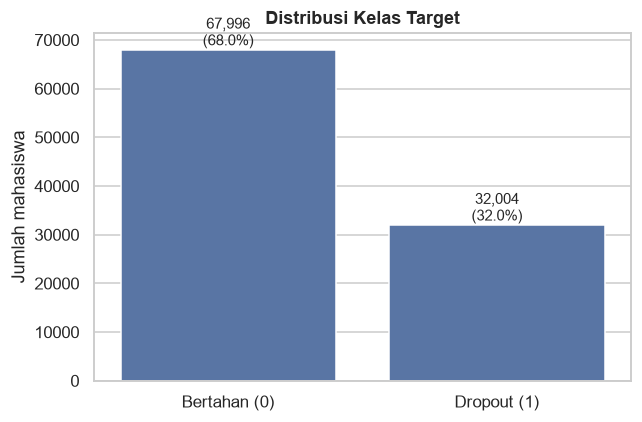

In [3]:
target_counts = df["dropout"].value_counts().sort_index()
target_pct = df["dropout"].value_counts(normalize=True).sort_index() * 100

ringkasan = pd.DataFrame({
    "Jumlah": target_counts,
    "Persentase (%)": target_pct.round(2),
})
ringkasan.index = ["Bertahan (0)", "Dropout (1)"]
display(ringkasan)

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="dropout", ax=ax)
ax.set_xticklabels(["Bertahan (0)", "Dropout (1)"])
ax.set_xlabel("")
ax.set_ylabel("Jumlah mahasiswa")
ax.set_title("Distribusi Kelas Target")
for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}\n({p.get_height() / len(df) * 100:.1f}%)",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center", va="bottom", fontsize=10,
    )
plt.tight_layout()
plt.show()

**Interpretasi.** Komposisi kelas adalah **68,0% bertahan (67.996)** dan **32,0% dropout (32.004)**, dengan rasio sekitar **2:1**.

Implikasinya:

- Kelas **tidak terlalu timpang**, sehingga **SMOTE tidak wajib**. Penanganan yang lebih sederhana dan lebih mudah dipertanggungjawabkan adalah `class_weight="balanced"` (Logistic Regression, Random Forest) atau `scale_pos_weight` (XGBoost).
- **Accuracy tidak boleh menjadi metrik utama.** Model yang selalu menebak "bertahan" sudah mendapat 68% accuracy tanpa belajar apa pun. Metrik utama harus berfokus pada kelas dropout: **Recall, F1, dan PR-AUC**.
- Dalam konteks early warning, **false negative** (mahasiswa berisiko diprediksi aman) lebih mahal daripada false positive, karena mahasiswa yang berisiko menjadi tidak mendapat intervensi.

## 3. Statistik Deskriptif

Statistik deskriptif dipakai untuk memeriksa rentang nilai, kemiringan distribusi (skewness), dan mendeteksi nilai yang tidak masuk akal.

In [4]:
desc = df.drop(columns=["person_id"]).describe().T
desc["skew"] = df.drop(columns=["person_id"]).skew(numeric_only=True)
display(desc.round(2))

,count,mean,std,min,25%,50%,75%,max,skew
age,100000.0,21.52,3.40,15.0,19.00,21.00,24.00,30.0,0.12
first_generation,100000.0,0.42,0.49,0.0,0.00,0.00,1.00,1.0,0.32
disability_status,100000.0,0.21,0.41,0.0,0.00,0.00,0.00,1.0,1.43
scholarship_holder,100000.0,0.59,0.49,0.0,0.00,1.00,1.00,1.0,-0.36
tuition_up_to_date,100000.0,0.78,0.41,0.0,1.00,1.00,1.00,1.0,-1.39
part_time_job,100000.0,0.48,0.50,0.0,0.00,0.00,1.00,1.0,0.07
weekly_work_hours,100000.0,8.74,10.23,0.0,0.00,0.00,18.00,40.0,0.67
semester,100000.0,3.62,2.11,1.0,2.00,3.00,5.00,8.0,0.44
international_student,100000.0,0.18,0.38,0.0,0.00,0.00,0.00,1.0,1.66
admission_grade,100000.0,133.15,28.26,5.5,114.10,133.10,152.50,200.0,-0.06


**Interpretasi.** Seluruh nilai berada pada rentang yang masuk akal: usia 15–30 tahun, IPK 0–4, tingkat kehadiran dan pengumpulan tugas 0–100%, `stress_level` dan `satisfaction_score` 1–10. Tidak ditemukan nilai mustahil seperti IPK negatif atau persentase di atas 100.

Beberapa fitur **miring ke kanan** (skew > 1): `weekly_work_hours`, `commute_time_mins`, `library_visits_per_month`, `lms_logins_per_week`, dan `missed_deadlines`. Artinya mayoritas mahasiswa bernilai rendah, tetapi ada sebagian kecil dengan nilai sangat tinggi. Ini relevan untuk Logistic Regression: transformasi `log1p` dapat membantu, sementara model berbasis pohon tidak terpengaruh.

## 4. Catatan Kualitas Data dan Potensi Leakage

Sebelum lanjut ke visualisasi, ada tiga hal struktural yang harus diperiksa karena akan menentukan keputusan preprocessing:

1. Apakah ada kolom identifier yang harus dibuang?
2. Apakah ada fitur yang saling redundan (kolinier sempurna)?
3. Apakah ada fitur yang **belum tersedia** pada saat prediksi (leakage)?

In [5]:
n_person_unik = df["person_id"].nunique()
redundansi_units = (df["units_passed"] == df["units_enrolled"] - df["units_failed"]).mean()
gpa2_turun = (df["gpa_semester_2"] < df["gpa_semester_1"]).mean()

print(f"person_id unik                    : {n_person_unik:,} / {len(df):,} baris")
print(f"units_passed = enrolled - failed  : {redundansi_units:.1%} baris")
print(f"gpa_semester_2 < gpa_semester_1   : {gpa2_turun:.1%} baris")
print()
print("Nilai unik kolom kategorikal:")
for col in ["gender", "nationality", "family_income_level", "course_type", "study_mode"]:
    print(f"  {col:<22}: {df[col].nunique():>2} -> {sorted(df[col].unique())}")

person_id unik                    : 100,000 / 100,000 baris
units_passed = enrolled - failed  : 100.0% baris
gpa_semester_2 < gpa_semester_1   : 90.4% baris

Nilai unik kolom kategorikal:
  gender                :  3 -> ['Female', 'Male', 'Other']
  nationality           : 15 -> ['Australia', 'Brazil', 'Canada', 'China', 'Egypt', 'Germany', 'India', 'Indonesia', 'Mexico', 'Nigeria', 'Pakistan', 'Philippines', 'South Korea', 'UK', 'USA']
  family_income_level   :  3 -> ['High', 'Low', 'Middle']
  course_type           :  5 -> ['Arts & Humanities', 'Business', 'Health Sciences', 'Law & Social Sciences', 'STEM']
  study_mode            :  3 -> ['Full-time', 'Online', 'Part-time']


**Interpretasi dan keputusan.**

1. **`person_id` → dibuang.** Nilainya unik 1–100.000, hanya identitas.
2. **`units_passed = units_enrolled − units_failed` pada 100% baris.** Ketiga kolom ini kolinier sempurna. Untuk model linear, cukup pertahankan dua kolom atau buat fitur turunan `pass_rate = units_passed / units_enrolled`. Model berbasis pohon lebih tahan, tetapi tetap lebih rapi bila redundansi dijelaskan.
3. **`gpa_semester_2 < gpa_semester_1` pada 90,4% baris.** Pola ini tidak lazim pada data nyata dan mengindikasikan dataset **sintetis atau hasil simulasi**. Ini bukan kesalahan analisis, tetapi wajib dicatat sebagai **keterbatasan** di laporan.
4. **`gpa_semester_2` → dibuang karena leakage.** Sesuai skenario prediksi di awal semester 2, nilai semester 2 belum tersedia. Memakainya akan membuat performa terlihat bagus tetapi tidak valid untuk penggunaan nyata.
5. **`semester` → dibuang.** Pada skenario awal semester 2, nilai ini seharusnya konstan. Variasi 1–8 pada dataset menunjukkan snapshot diambil pada berbagai tahap, sehingga tidak konsisten dengan skenario.

## 5. Distribusi Fitur Numerik

Histogram membantu melihat bentuk distribusi: simetris, miring, atau diskret. Distribusi yang sangat miring perlu perhatian khusus pada model linear.

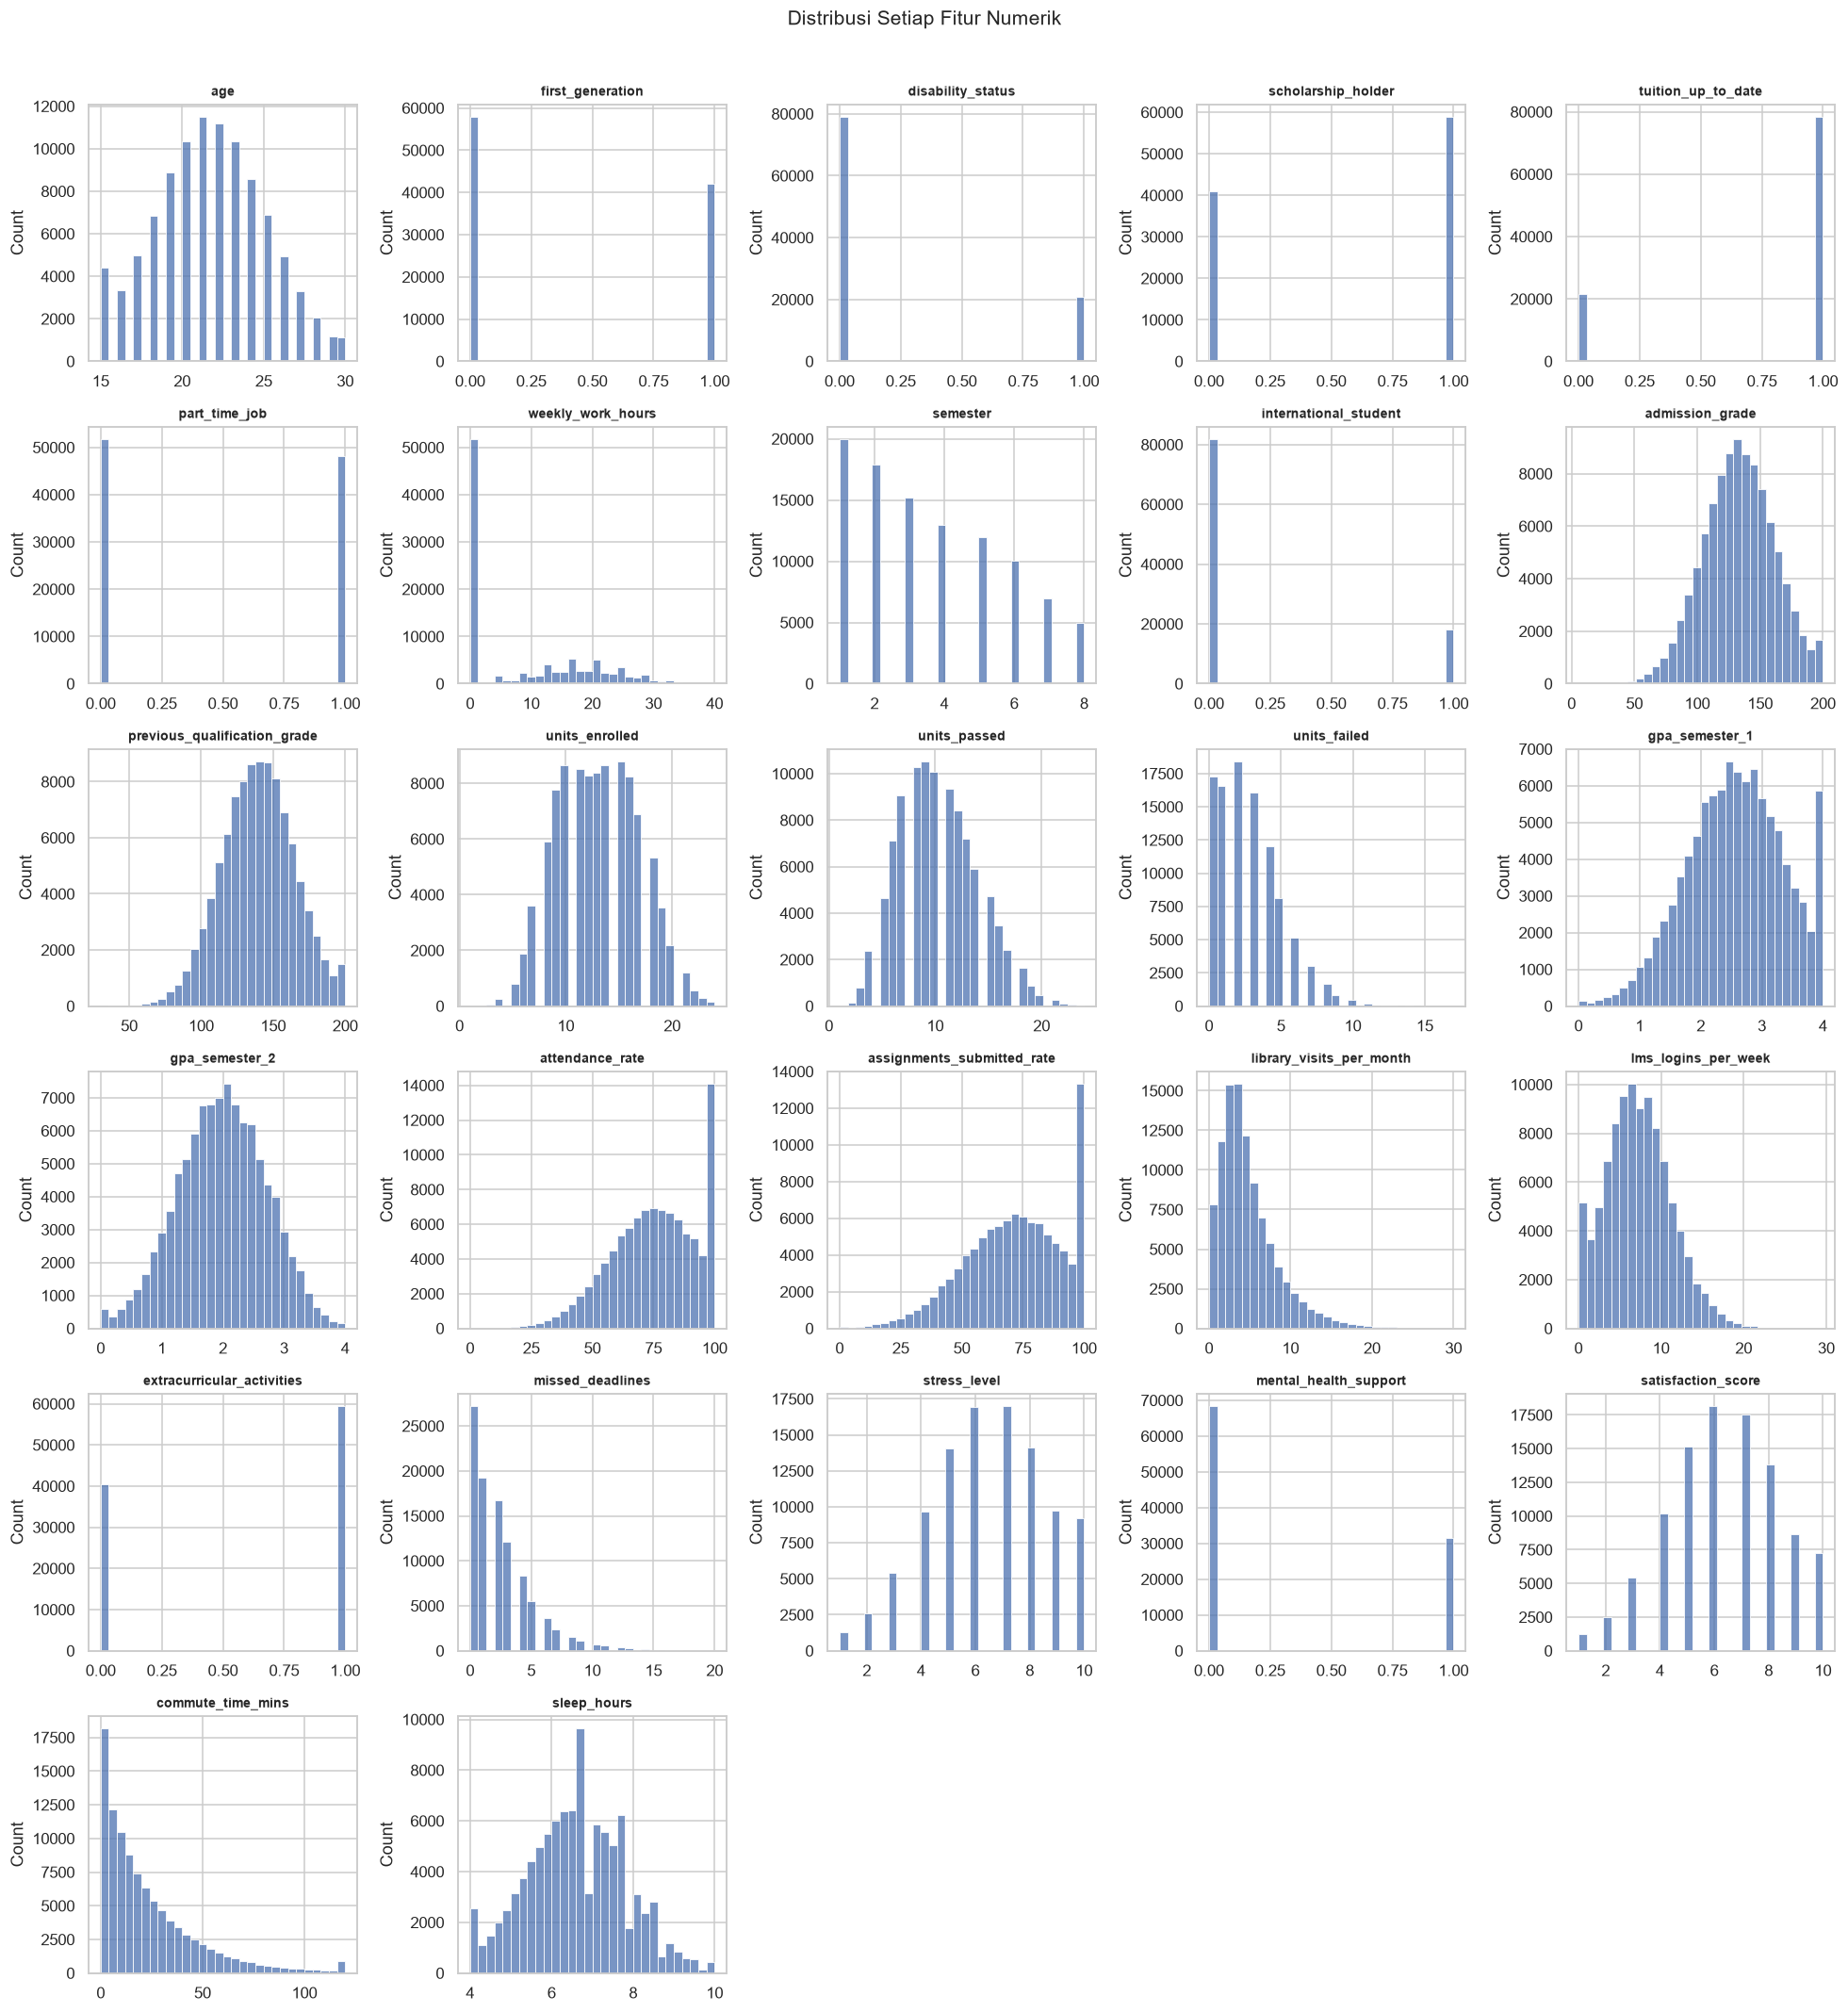

In [6]:
num_cols = [
    c for c in df.select_dtypes("number").columns
    if c not in ("person_id", "dropout")
]

n = len(num_cols)
ncols = 5
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(18, 3.2 * nrows))
axes = axes.ravel()
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
for ax in axes[n:]:
    ax.axis("off")
plt.suptitle("Distribusi Setiap Fitur Numerik", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Interpretasi.** Pola distribusi terbagi menjadi tiga kelompok:

- **Mendekati normal / simetris:** `age`, `admission_grade`, `previous_qualification_grade`, `gpa_semester_1`, `gpa_semester_2`, `attendance_rate`, `assignments_submitted_rate`, `sleep_hours`.
- **Miring ke kanan:** `weekly_work_hours`, `commute_time_mins`, `library_visits_per_month`, `lms_logins_per_week`, `missed_deadlines`, `units_failed`. Sebagian besar mahasiswa bernilai rendah, sebagian kecil sangat tinggi.
- **Diskret / ordinal:** `stress_level`, `satisfaction_score` (1–10), `semester` (1–8), serta kolom biner 0/1.

Konsekuensi praktis: transformasi `log1p` bermanfaat untuk kelompok miring ketika memakai Logistic Regression. Untuk Random Forest dan XGBoost, transformasi ini tidak diperlukan karena kedua model berbasis pemisahan threshold.

## 6. Pemeriksaan Outlier

Outlier dideteksi dengan aturan IQR (di luar Q1 − 1,5·IQR dan Q3 + 1,5·IQR). Tujuannya bukan otomatis menghapus, tetapi memahami apakah nilai ekstrem tersebut wajar.

In [7]:
outlier_rows = []
for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    outlier_rows.append({
        "Fitur": col,
        "Batas Bawah": lo,
        "Batas Atas": hi,
        "Jumlah Outlier": n_out,
        "Persentase (%)": n_out / len(df) * 100,
    })

outlier_df = pd.DataFrame(outlier_rows).sort_values("Persentase (%)", ascending=False)
display(outlier_df.round(2).head(15))

,Fitur,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
4,tuition_up_to_date,1.00,1.00,21514,21.51
2,disability_status,0.00,0.00,20877,20.88
8,international_student,0.00,0.00,18094,18.09
21,missed_deadlines,-4.50,7.50,4903,4.90
25,commute_time_mins,-34.50,73.50,4879,4.88
18,library_visits_per_month,-4.00,12.00,3756,3.76
13,units_failed,-3.50,8.50,1628,1.63
19,lms_logins_per_week,-3.45,17.75,823,0.82
12,units_passed,0.50,20.50,436,0.44
14,gpa_semester_1,0.38,4.78,359,0.36


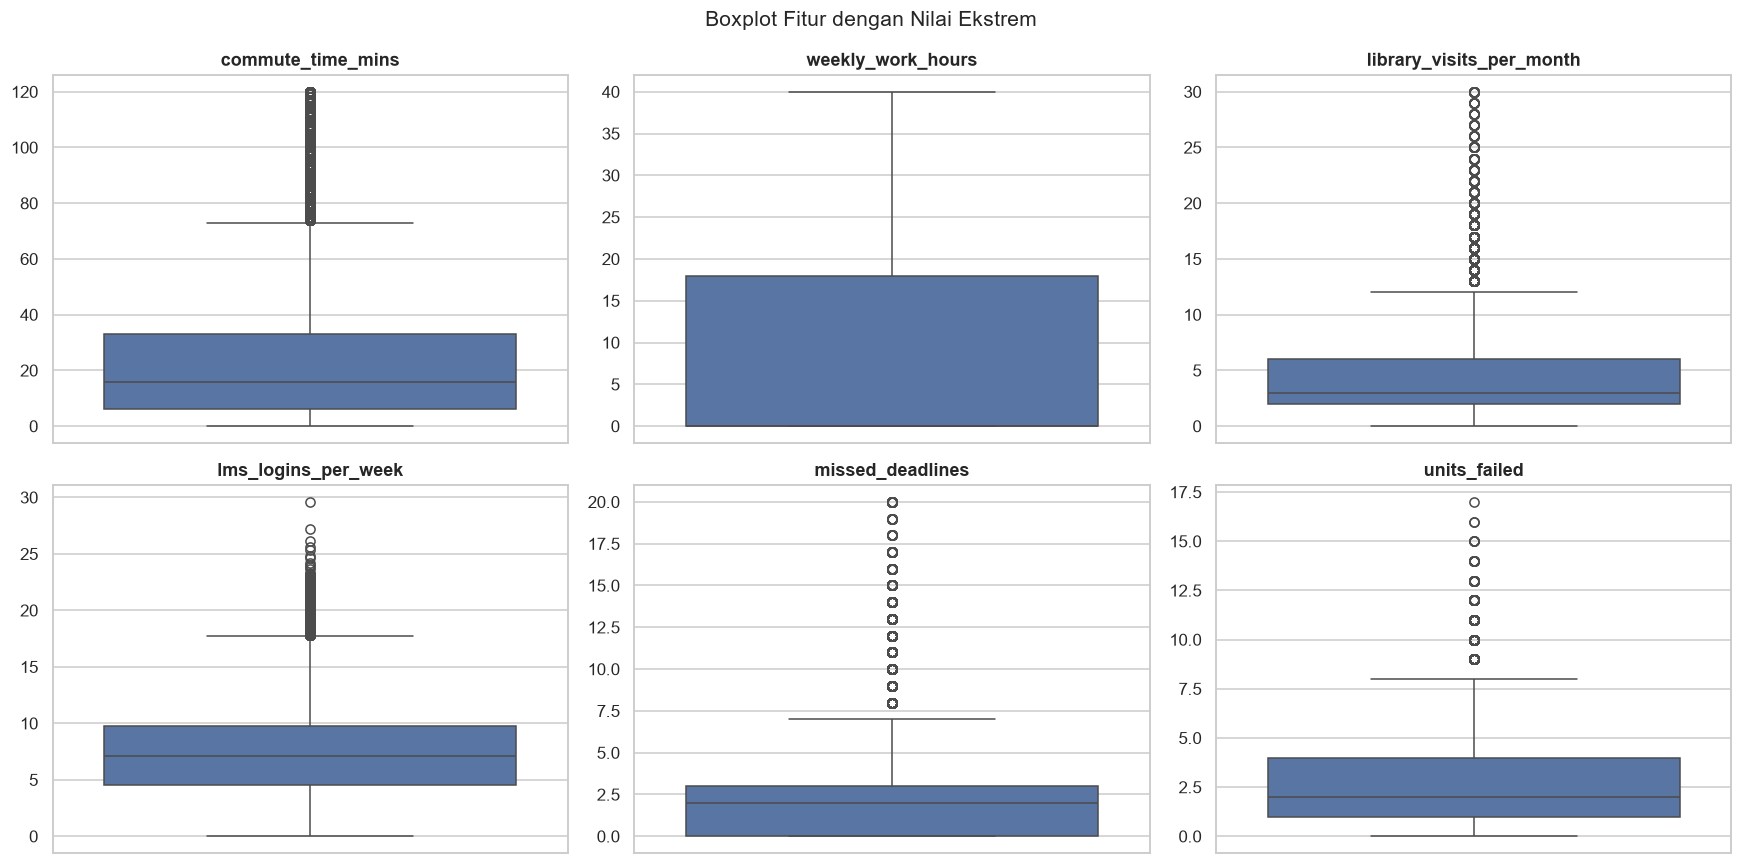

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
box_cols = ["commute_time_mins", "weekly_work_hours", "library_visits_per_month",
            "lms_logins_per_week", "missed_deadlines", "units_failed"]
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(data=df, y=col, ax=ax, color="#4C72B0")
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Boxplot Fitur dengan Nilai Ekstrem", fontsize=14)
plt.tight_layout()
plt.show()

**Interpretasi.** Secara statistik banyak nilai terdeteksi sebagai outlier, tetapi setelah diperiksa **semuanya masih masuk akal secara domain**: mahasiswa yang bekerja 40 jam/minggu, pulang-pergi 120 menit, atau meminjam 30 buku per bulan adalah kondisi nyata, bukan kesalahan input.

**Keputusan: outlier tidak dihapus.** Alasannya:

- Nilai ekstrem justru berpotensi menjadi sinyal dropout (misalnya jam kerja sangat tinggi berkaitan dengan beban ganda).
- Menghapus outlier berisiko membuang mahasiswa berisiko tinggi — bertentangan dengan tujuan early warning.
- Random Forest dan XGBoost relatif tahan terhadap outlier. Untuk Logistic Regression, StandardScaler dan `log1p` sudah cukup meredam pengaruhnya.

## 7. Perbandingan Fitur Numerik: Bertahan vs Dropout

Boxplot dan tabel rata-rata menunjukkan seberapa besar perbedaan karakteristik antara kedua kelas. Ini adalah inti dari pertanyaan "fitur apa yang berhubungan dengan dropout".

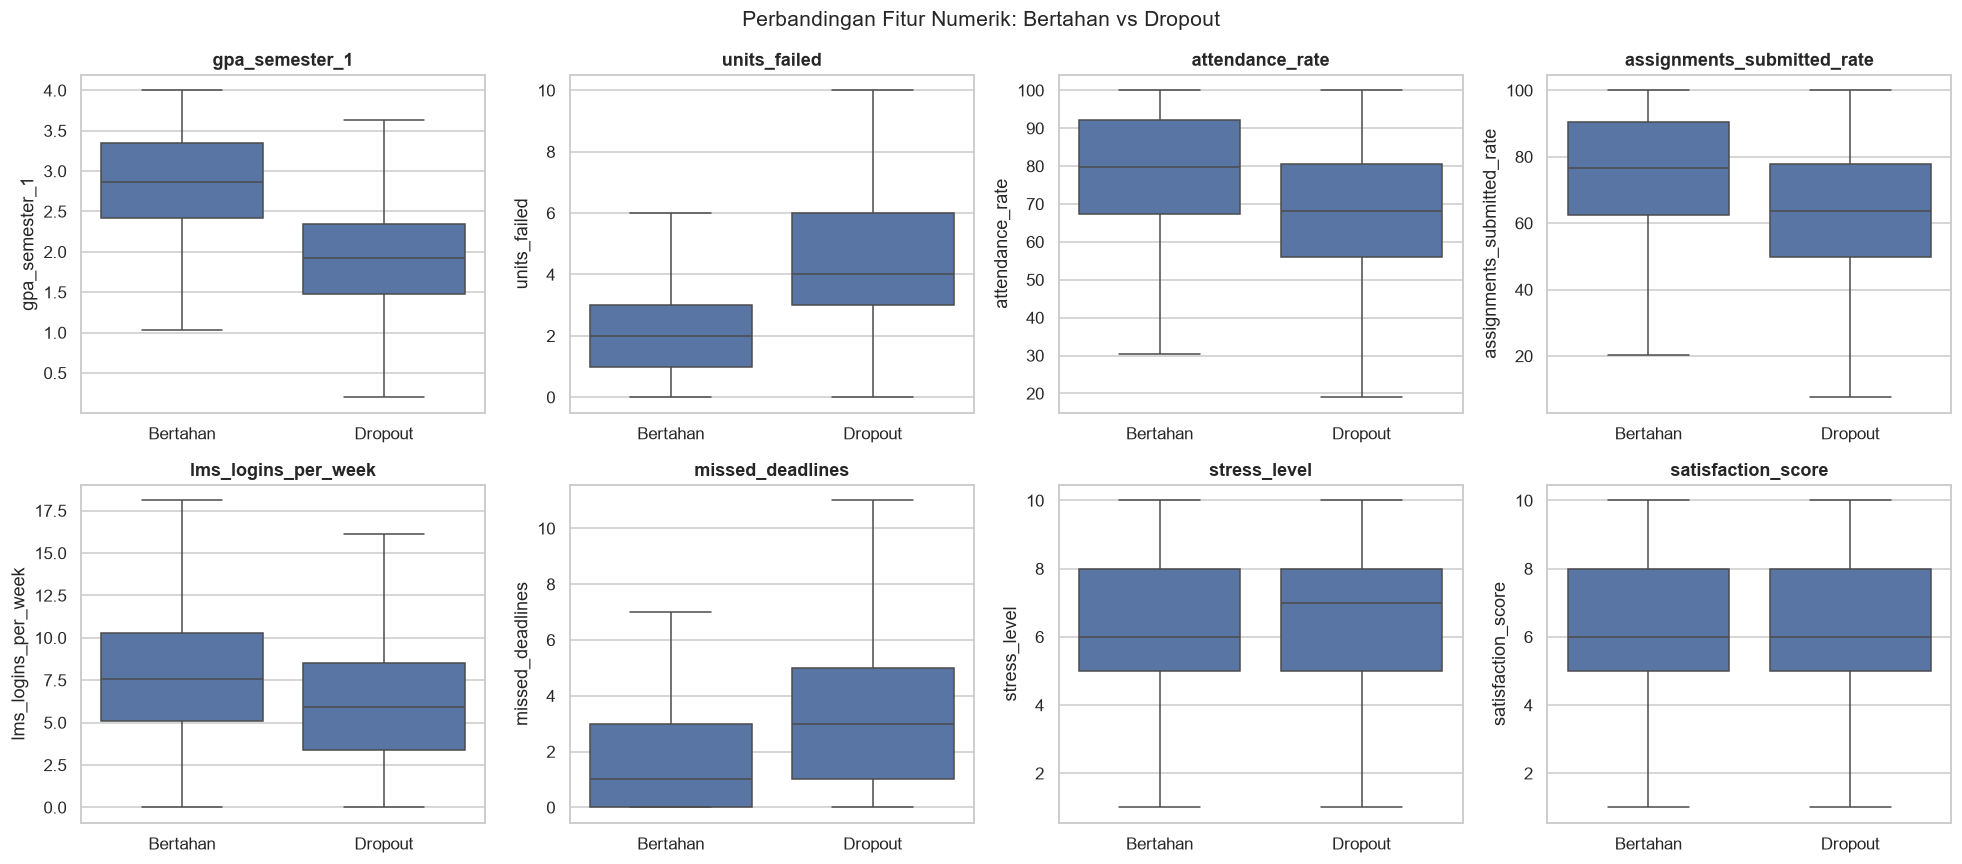

In [9]:
box_cols = ["gpa_semester_1", "units_failed", "attendance_rate", "assignments_submitted_rate",
            "lms_logins_per_week", "missed_deadlines", "stress_level", "satisfaction_score"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(data=df, x="dropout", y=col, ax=ax, showfliers=False)
    ax.set_xticklabels(["Bertahan", "Dropout"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.suptitle("Perbandingan Fitur Numerik: Bertahan vs Dropout", fontsize=14)
plt.tight_layout()
plt.show()

In [10]:
mean_cols = ["gpa_semester_1", "units_failed", "attendance_rate",
             "assignments_submitted_rate", "lms_logins_per_week",
             "library_visits_per_month", "missed_deadlines", "stress_level",
             "satisfaction_score", "weekly_work_hours"]

ringkasan_mean = df.groupby("dropout")[mean_cols].mean().T
ringkasan_mean.columns = ["Bertahan (0)", "Dropout (1)"]
ringkasan_mean["Selisih"] = ringkasan_mean["Dropout (1)"] - ringkasan_mean["Bertahan (0)"]
display(ringkasan_mean.round(2))

,Bertahan (0),Dropout (1),Selisih
gpa_semester_1,2.88,1.91,-0.96
units_failed,2.01,4.22,2.22
attendance_rate,78.50,67.87,-10.63
assignments_submitted_rate,75.18,63.44,-11.74
lms_logins_per_week,7.82,6.12,-1.70
library_visits_per_month,4.93,3.17,-1.76
missed_deadlines,1.87,3.44,1.56
stress_level,6.26,6.86,0.60
satisfaction_score,6.44,6.06,-0.38
weekly_work_hours,7.47,11.45,3.97


**Interpretasi.** Perbedaan kedua kelas sangat jelas dan konsisten:

| Fitur | Bertahan | Dropout | Arah |
|---|---:|---:|---|
| `gpa_semester_1` | 2,88 | 1,91 | Dropout **lebih rendah** |
| `units_failed` | 2,01 | 4,22 | Dropout **lebih tinggi** |
| `attendance_rate` | 78,5 | 67,9 | Dropout **lebih rendah** |
| `assignments_submitted_rate` | 75,2 | 63,4 | Dropout **lebih rendah** |
| `lms_logins_per_week` | 7,82 | 6,12 | Dropout **lebih rendah** |
| `library_visits_per_month` | 4,93 | 3,17 | Dropout **lebih rendah** |
| `missed_deadlines` | 1,87 | 3,44 | Dropout **lebih tinggi** |
| `stress_level` | 6,26 | 6,86 | Dropout **sedikit lebih tinggi** |
| `satisfaction_score` | 6,44 | 6,06 | Dropout **sedikit lebih rendah** |
| `weekly_work_hours` | 7,47 | 11,45 | Dropout **lebih tinggi** |

Kesimpulan sementara: **faktor akademik dan keterlibatan belajar** (`gpa_semester_1`, `units_failed`, kehadiran, pengumpulan tugas, LMS, keterlambatan) memiliki daya pisah paling kuat. Faktor psikologis dan beban kerja memberi sinyal tambahan, tetapi lebih lemah. Ini masuk akal dan mudah dijelaskan saat presentasi.

## 8. Fitur Kategorikal vs Target

Untuk fitur kategorikal, yang dibandingkan bukan rata-rata, melainkan **tingkat dropout (%)** pada setiap kategori. Tujuannya menilai apakah faktor demografis dan administratif cukup informatif.

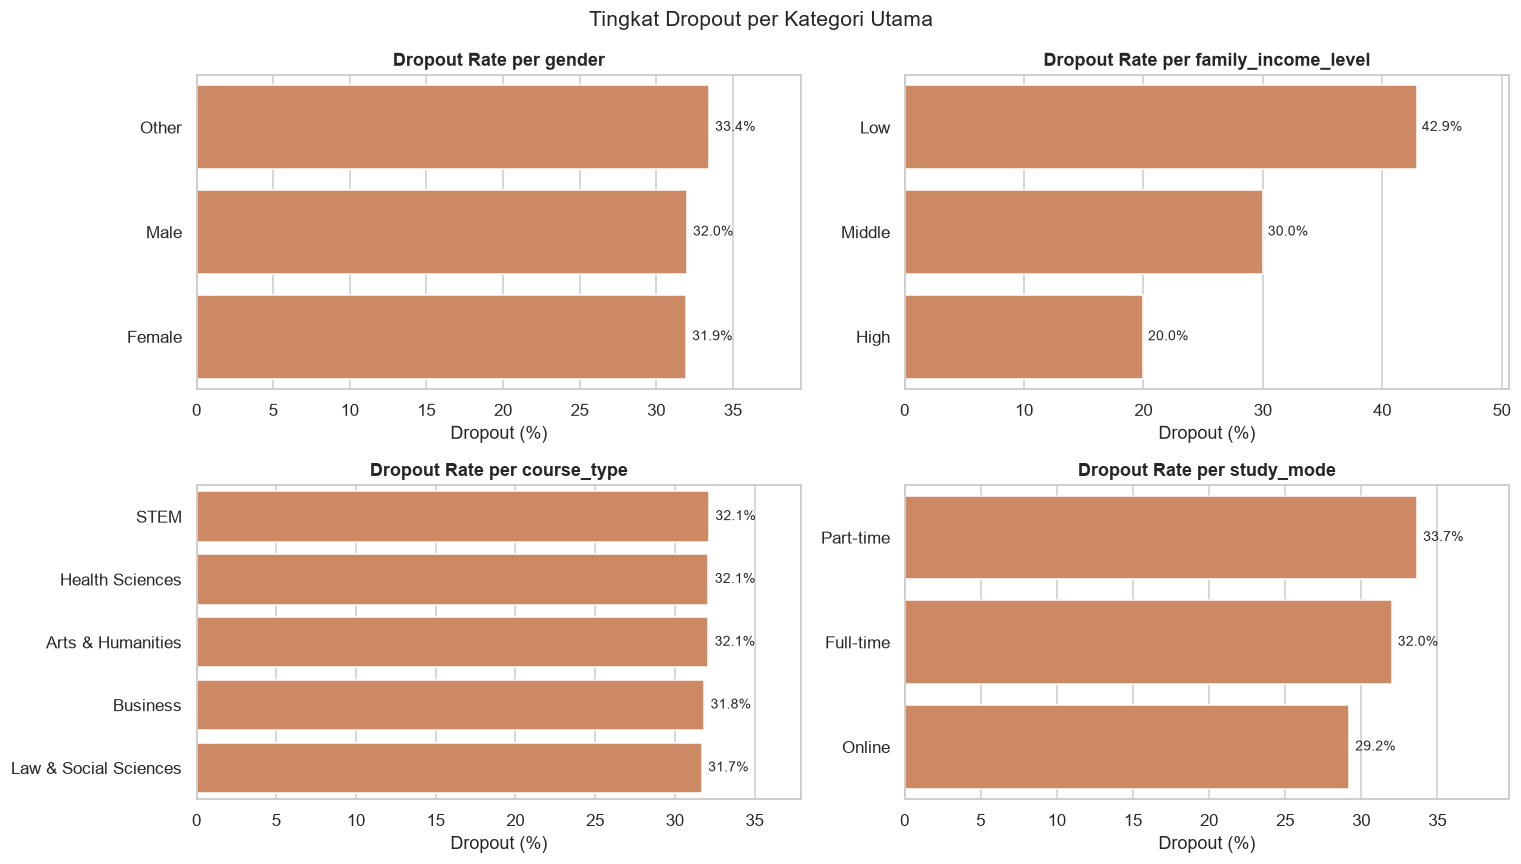

In [11]:
cat_cols = ["gender", "family_income_level", "course_type", "study_mode"]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = (df.groupby(col)["dropout"].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color="#DD8452")
    ax.set_title(f"Dropout Rate per {col}")
    ax.set_xlabel("Dropout (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, max(rate.values) * 1.18)
    for i, v in enumerate(rate.values):
        ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9)
plt.suptitle("Tingkat Dropout per Kategori Utama", fontsize=14)
plt.tight_layout()
plt.show()

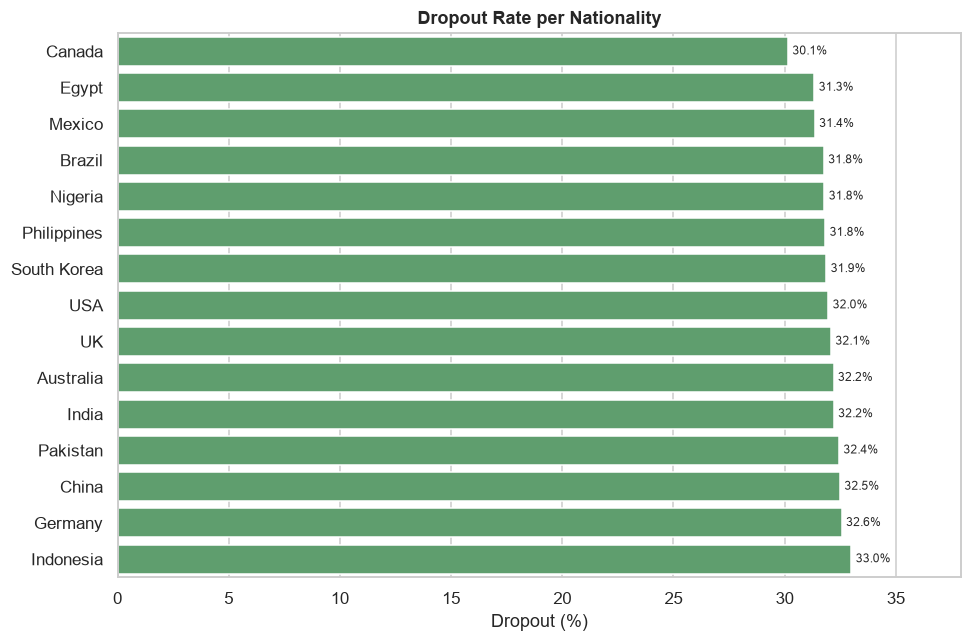

In [12]:
rate_nat = (df.groupby("nationality")["dropout"].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=rate_nat.values, y=rate_nat.index, ax=ax, color="#55A868")
ax.set_title("Dropout Rate per Nationality")
ax.set_xlabel("Dropout (%)")
ax.set_ylabel("")
ax.set_xlim(0, max(rate_nat.values) * 1.15)
for i, v in enumerate(rate_nat.values):
    ax.text(v + 0.2, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout()
plt.show()

**Interpretasi.**

- **`family_income_level` adalah faktor demografis yang paling jelas:** dropout **42,9%** pada keluarga berpenghasilan rendah, **30,0%** menengah, dan **20,0%** tinggi. Selisih >20 poin persentase menunjukkan status ekonomi berperan penting.
- **`gender` hampir tidak membedakan:** 31,9%–33,4%. Tidak ada sinyal berarti.
- **`course_type` praktis seragam:** 31,7%–32,1% di semua program studi.
- **`study_mode`** hanya berbeda tipis: part-time 33,7%, full-time 32,0%, online 29,2%.
- **`nationality`** juga relatif seragam (30,1%–33,0%), meskipun jumlah mahasiswa per negara tidak seimbang.

Kesimpulan: **fitur demografis lemah, kecuali tingkat pendapatan keluarga.** Ini penting untuk analisis feature importance nanti — jangan heran bila `gender`, `course_type`, dan `nationality` mendapat skor rendah.

## 9. Korelasi Antar Fitur

Heatmap korelasi memberi gambaran linear tentang hubungan setiap fitur dengan target sekaligus mendeteksi multikolinearitas antarfitur.

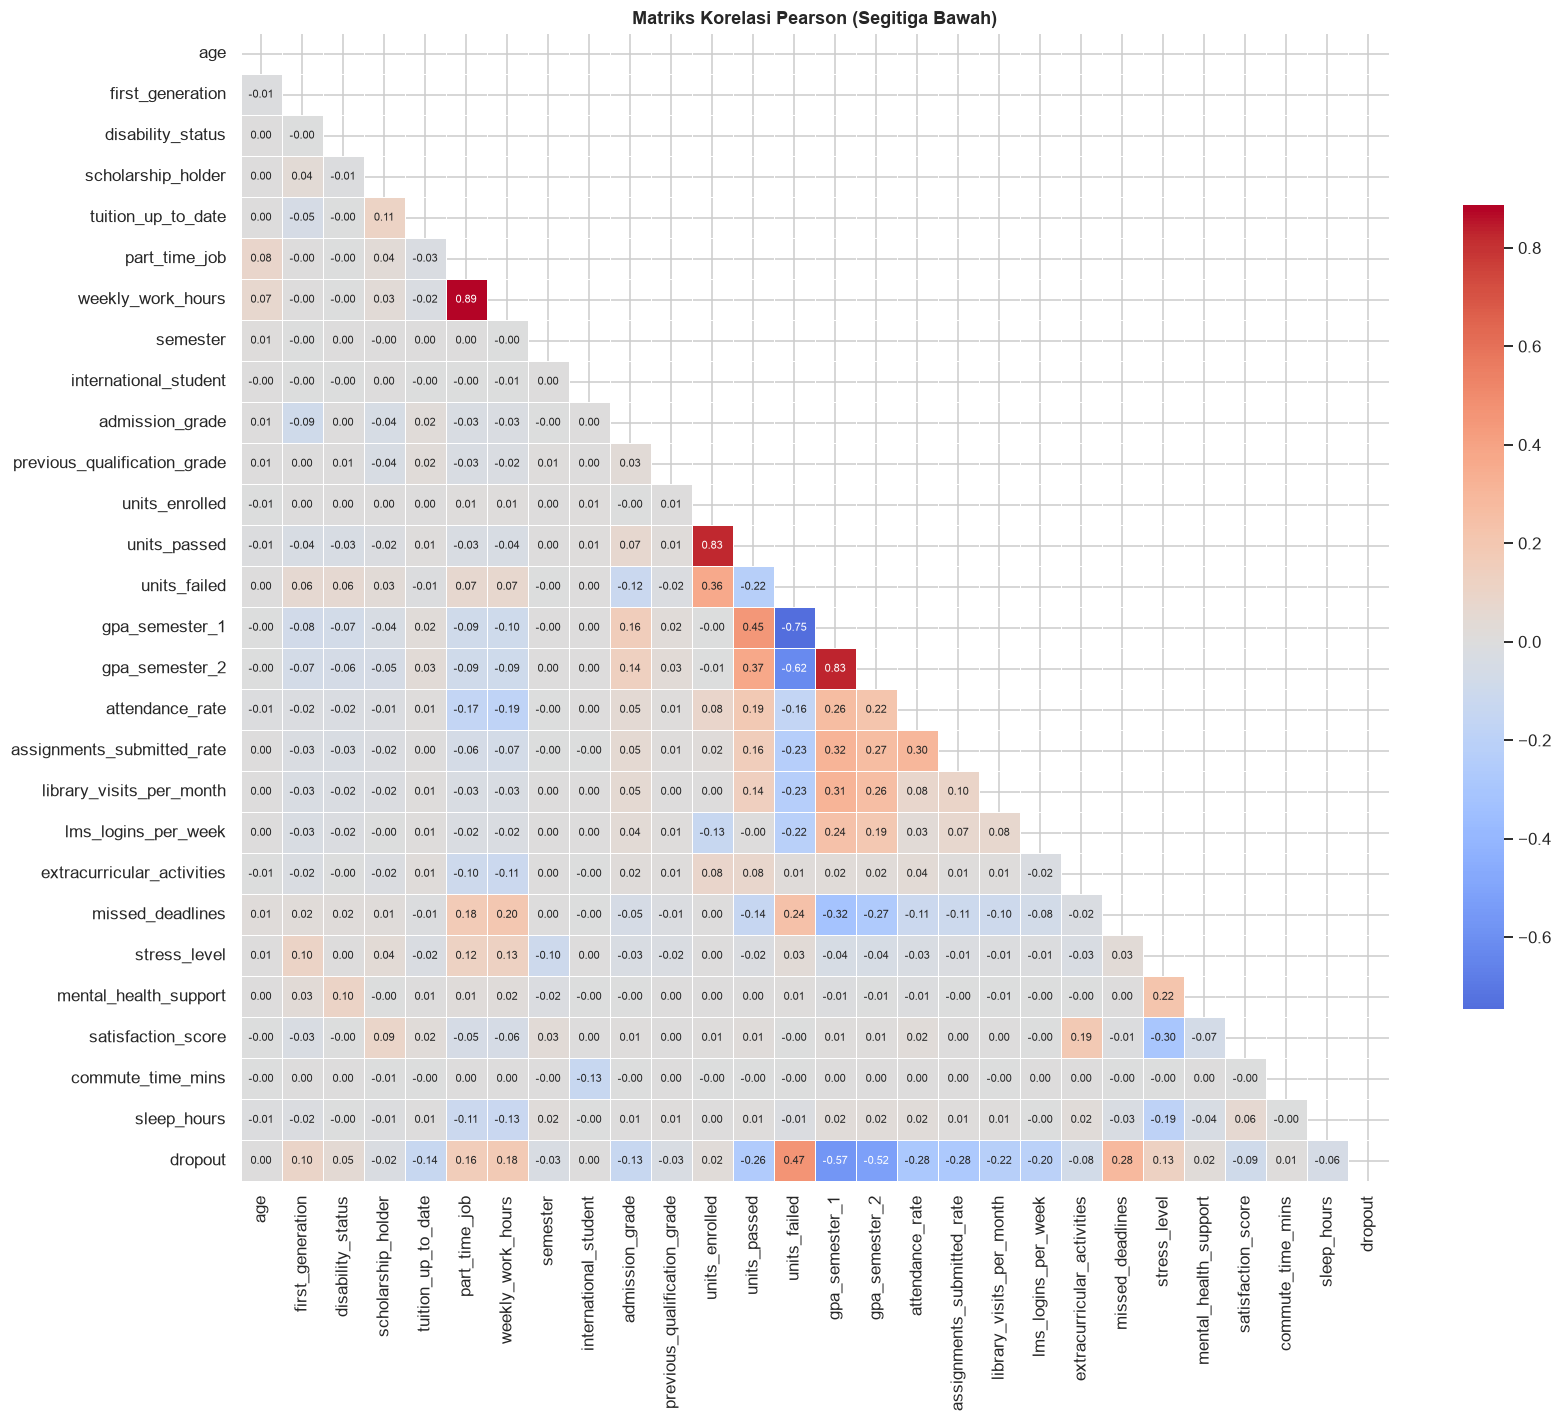

Korelasi fitur dengan dropout (diurutkan berdasarkan |r|):


,r
gpa_semester_1,-0.569
gpa_semester_2,-0.521
units_failed,0.467
attendance_rate,-0.285
missed_deadlines,0.282
assignments_submitted_rate,-0.275
units_passed,-0.261
library_visits_per_month,-0.224
lms_logins_per_week,-0.202
weekly_work_hours,0.181


In [13]:
corr_cols = [c for c in df.select_dtypes("number").columns if c != "person_id"]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    square=True, linewidths=0.4, cbar_kws={"shrink": 0.7},
    annot_kws={"size": 7}, ax=ax,
)
ax.set_title("Matriks Korelasi Pearson (Segitiga Bawah)")
plt.tight_layout()
plt.show()

print("Korelasi fitur dengan dropout (diurutkan berdasarkan |r|):")
tbl = corr["dropout"].drop("dropout").sort_values(key=abs, ascending=False).round(3)
display(tbl.to_frame("r"))

**Interpretasi.** Korelasi linear terkuat dengan `dropout`:

| Fitur | r | Makna |
|---|---:|---|
| `gpa_semester_1` | **−0,569** | IPK semester 1 tinggi → risiko dropout rendah |
| `units_failed` | **+0,467** | Makin banyak mata kuliah gagal → risiko naik |
| `attendance_rate` | −0,285 | Kehadiran tinggi → risiko turun |
| `assignments_submitted_rate` | −0,275 | Tugas terkumpul → risiko turun |
| `units_passed` | −0,261 | Mata kuliah lulus → risiko turun |
| `library_visits_per_month` | −0,224 | Aktivitas belajar → risiko turun |
| `lms_logins_per_week` | −0,202 | Keterlibatan digital → risiko turun |
| `weekly_work_hours` | +0,181 | Jam kerja tinggi → risiko naik |

Catatan penting:

- **Korelasi ≠ kausalitas.** Hubungan ini asosiatif, bukan bukti sebab-akibat.
- **Multikolinearitas** terlihat pada `units_enrolled`–`units_passed`–`units_failed` dan `gpa_semester_1`–`gpa_semester_2`. Untuk Logistic Regression, ini bisa membuat koefisien tidak stabil, sehingga perlu dipilih salah satu atau dibuat fitur turunan.
- `gpa_semester_2` sengaja tidak dipakai pada pemodelan karena leakage, meskipun korelasinya tinggi.

## 10. Analisis Band (Rentang Nilai)

Korelasi hanya menangkap hubungan linear. Analisis band memecah fitur menjadi beberapa rentang untuk melihat apakah hubungannya **tidak linear** atau memiliki **titik kritis** — informasi yang sangat berguna untuk aplikasi dan rekomendasi.

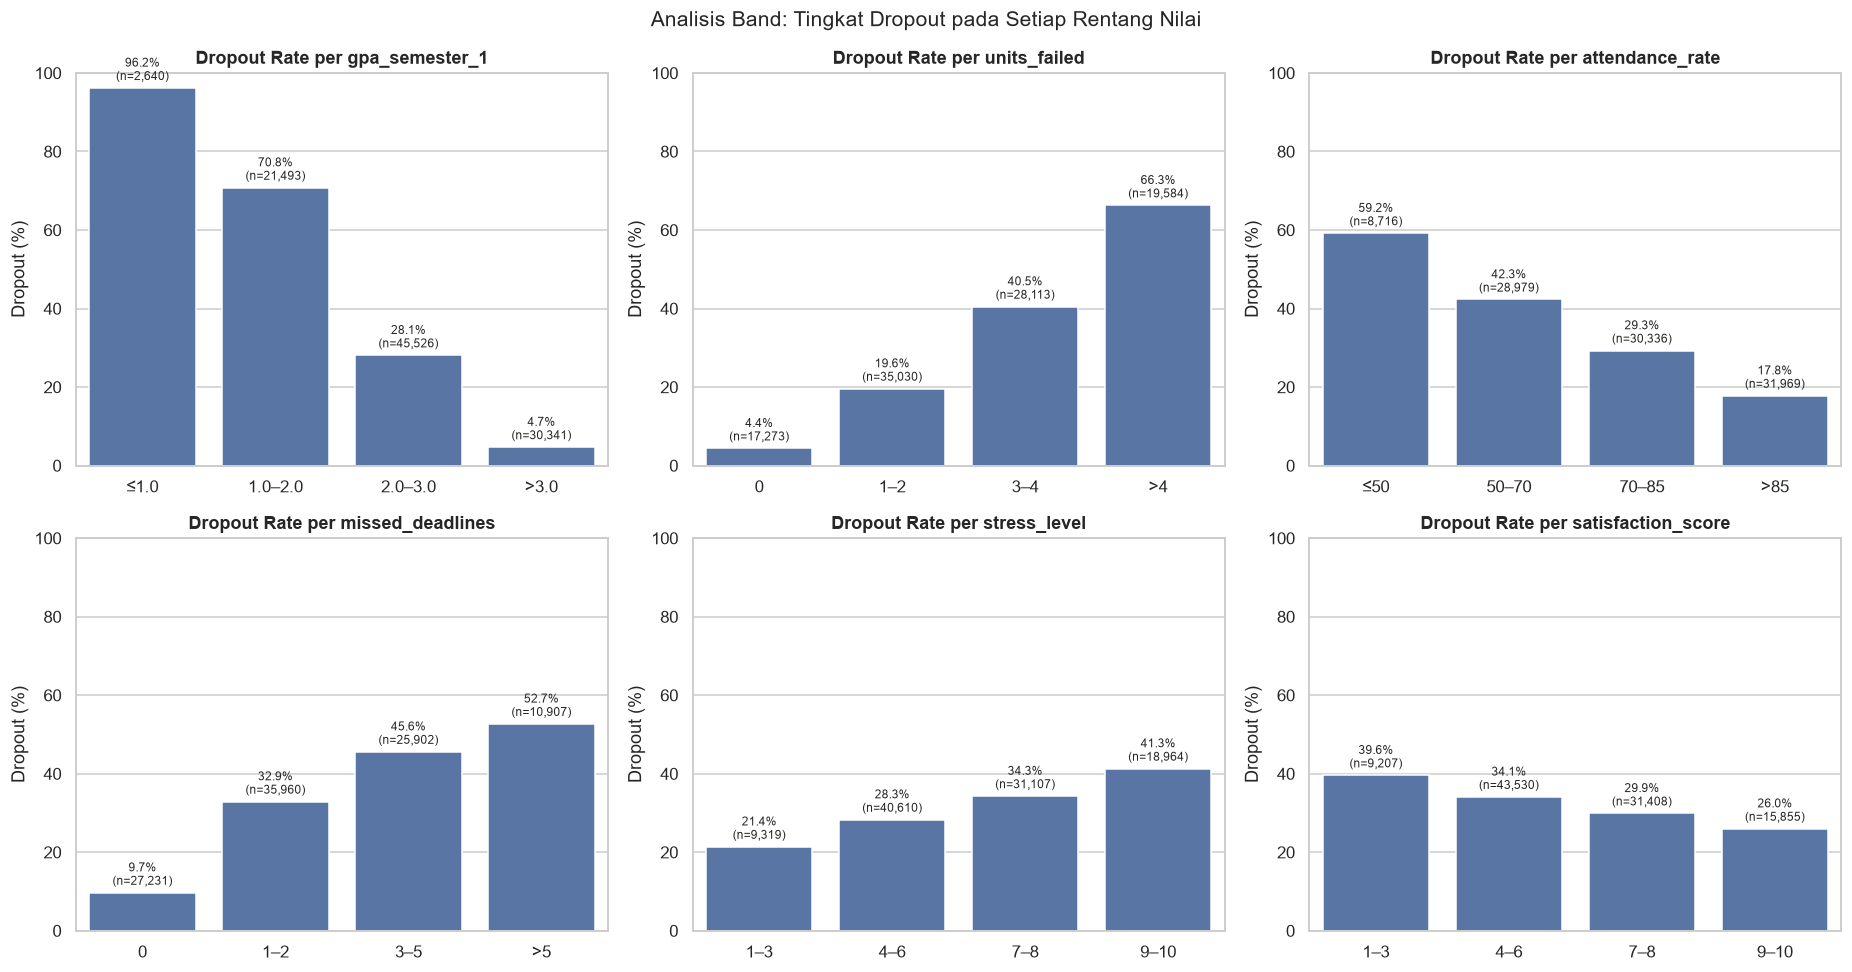

In [14]:
def dropout_by_band(col, bins, labels):
    band = pd.cut(df[col], bins=bins, labels=labels, include_lowest=True)
    hasil = df.groupby(band, observed=True)["dropout"].agg(["mean", "size"])
    hasil["mean"] = (hasil["mean"] * 100).round(1)
    hasil.columns = ["Dropout (%)", "Jumlah"]
    return hasil


spesifikasi = [
    ("gpa_semester_1", [-0.01, 1, 2, 3, 4], ["≤1.0", "1.0–2.0", "2.0–3.0", ">3.0"]),
    ("units_failed", [-0.01, 0, 2, 4, 17], ["0", "1–2", "3–4", ">4"]),
    ("attendance_rate", [-0.01, 50, 70, 85, 100], ["≤50", "50–70", "70–85", ">85"]),
    ("missed_deadlines", [-0.01, 0, 2, 5, 20], ["0", "1–2", "3–5", ">5"]),
    ("stress_level", [0, 3, 6, 8, 10], ["1–3", "4–6", "7–8", "9–10"]),
    ("satisfaction_score", [0, 3, 6, 8, 10], ["1–3", "4–6", "7–8", "9–10"]),
]

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (col, bins, labels) in zip(axes.ravel(), spesifikasi):
    tbl = dropout_by_band(col, bins, labels)
    sns.barplot(x=tbl.index.astype(str), y=tbl["Dropout (%)"], ax=ax, color="#4C72B0")
    ax.set_title(f"Dropout Rate per {col}")
    ax.set_xlabel("")
    ax.set_ylabel("Dropout (%)")
    ax.set_ylim(0, 100)
    for i, (v, n) in enumerate(zip(tbl["Dropout (%)"], tbl["Jumlah"])):
        ax.text(i, v + 2, f"{v:.1f}%\n(n={n:,})", ha="center", fontsize=8)
plt.suptitle("Analisis Band: Tingkat Dropout pada Setiap Rentang Nilai", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
for col, bins, labels in spesifikasi:
    print(f"=== {col} ===")
    display(dropout_by_band(col, bins, labels))
    print()

=== gpa_semester_1 ===


,Dropout (%),Jumlah
gpa_semester_1,,
≤1.0,96.2,2640
1.0–2.0,70.8,21493
2.0–3.0,28.1,45526
>3.0,4.7,30341



=== units_failed ===


,Dropout (%),Jumlah
units_failed,,
0,4.4,17273
1–2,19.6,35030
3–4,40.5,28113
>4,66.3,19584



=== attendance_rate ===


,Dropout (%),Jumlah
attendance_rate,,
≤50,59.2,8716
50–70,42.3,28979
70–85,29.3,30336
>85,17.8,31969


... (2 outputs left out)


=== stress_level ===


,Dropout (%),Jumlah
stress_level,,
1–3,21.4,9319
4–6,28.3,40610
7–8,34.3,31107
9–10,41.3,18964



=== satisfaction_score ===


,Dropout (%),Jumlah
satisfaction_score,,
1–3,39.6,9207
4–6,34.1,43530
7–8,29.9,31408
9–10,26.0,15855


**Interpretasi — ada titik kritis yang sangat tajam.**

| Fitur | Rentang | Dropout | Insight |
|---|---|---:|---|
| `gpa_semester_1` | ≤1,0 | **96,2%** | Nyaris pasti dropout |
| | 1,0–2,0 | 70,8% | Risiko sangat tinggi |
| | 2,0–3,0 | 28,1% | Risiko sedang |
| | >3,0 | **4,7%** | Risiko rendah |
| `units_failed` | 0 | **9,7%** | Sangat rendah |
| | 1–2 | 32,9% | Sedang |
| | 3–4 | 45,6% | Tinggi |
| | >4 | **52,7%** | Sangat tinggi |
| `attendance_rate` | ≤50% | 59,2% | Tinggi |
| | >85% | **17,8%** | Rendah |
| `missed_deadlines` | 0 | **9,7%** | Sangat rendah |
| | >5 | **52,7%** | Sangat tinggi |
| `stress_level` | 1–3 | 21,4% | Rendah |
| | 9–10 | **41,3%** | Tinggi |
| `satisfaction_score` | 1–3 | 39,6% | Tinggi |
| | 9–10 | 26,0% | Lebih rendah |

Temuan paling penting: **hubungan antara IPK semester 1 dan dropout tidak linear, melainkan memiliki ambang batas.** IPK ≤ 2,0 dikaitkan dengan dropout di atas 70%. Ini justru menguntungkan model berbasis pohon (Random Forest, XGBoost) yang mampu menangkap threshold secara alami, sementara Logistic Regression perlu fitur tambahan atau transformasi agar menangkap pola ini.

Analisis band juga langsung menghasilkan **aturan bisnis untuk aplikasi**: kategori risiko dapat dibuat dari ambang yang punya makna, bukan sekadar membagi probabilitas menjadi tiga bagian sama besar.

## 11. Ringkasan Temuan dan Implikasi

### Temuan utama

1. **Dataset bersih:** 100.000 baris, 34 kolom, tanpa missing value dan duplikat.
2. **Kelas cukup seimbang (68:32):** tidak perlu SMOTE; cukup `class_weight`/`scale_pos_weight`.
3. **Faktor akademik paling menentukan:** `gpa_semester_1` (r = −0,569) dan `units_failed` (r = +0,467).
4. **Keterlibatan belajar konsisten membedakan kelas:** kehadiran, pengumpulan tugas, LMS, kunjungan perpustakaan, dan keterlambatan.
5. **Faktor ekonomi berperan:** dropout 42,9% pada pendapatan rendah vs 20,0% pada pendapatan tinggi.
6. **Faktor demografis lain lemah:** gender, program studi, dan kewarganegaraan hampir seragam.
7. **Hubungan tidak linear:** ada titik kritis pada IPK ≤ 2,0 dan `units_failed` > 4.
8. **Indikasi data sintetis:** `gpa_semester_2 < gpa_semester_1` pada 90,4% baris — wajib dicatat sebagai keterbatasan.

### Keputusan untuk tahap berikutnya

| Tahap | Keputusan |
|---|---|
| Drop kolom | `person_id`, `gpa_semester_2`, `semester` |
| Redundansi | Buat `pass_rate`/`fail_rate`, atau pertahankan `units_enrolled` + `units_failed` |
| Missing value | Tidak perlu imputasi |
| Outlier | Tidak dihapus (masih wajar secara domain) |
| Encoding | One-hot untuk 5 kolom kategorikal |
| Scaling | StandardScaler untuk Logistic Regression; tidak perlu untuk RF/XGBoost |
| Transformasi | `log1p` untuk fitur miring pada model linear |
| Imbalance | `class_weight="balanced"` / `scale_pos_weight` |
| Split | 80:20 stratified, `random_state=42` |
| CV | 5-fold StratifiedKFold |
| Metrik utama | Recall kelas dropout, F1, PR-AUC |

### Catatan untuk laporan

- Setiap visualisasi di atas sudah disertai interpretasi, bukan sekadar ditampilkan.
- Asumsi yang harus ditulis: fitur keterlibatan (`attendance_rate`, `assignments_submitted_rate`, `lms_logins_per_week`, `library_visits_per_month`, `missed_deadlines`) dianggap merekam **semester 1**.
- Keterbatasan sumber data (Kaggle, indikasi sintetis) perlu dinyatakan terbuka pada bagian keterbatasan.